# Retail Customer Analysis
**Author:** Amal Shesnij

Analysis of retail transactions, customers and products to answer 11 business questions (AnalytixLabs case study).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.2f}'.format)

customer = pd.read_csv('Customer.csv')
print(customer.shape)

(5647, 4)


## Step 1: Load and inspect the data

In [2]:
transactions = pd.read_csv('Transactions.csv')
prod_cat = pd.read_csv('prod_cat_info.csv')

print('Customer     :', customer.shape)
print('Transactions :', transactions.shape)
print('Product info :', prod_cat.shape)

Customer     : (5647, 4)
Transactions : (23053, 10)
Product info : (23, 4)


In [3]:
transactions.head()

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.30,"-4,265.30",e-Shop
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.92,"-8,270.92",e-Shop
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.11,"-1,748.11",TeleShop
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.35,"-4,518.35",e-Shop
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.11,"-1,748.11",TeleShop


In [4]:
transactions.dtypes

transaction_id        int64
cust_id               int64
tran_date               str
prod_subcat_code      int64
prod_cat_code         int64
Qty                   int64
Rate                  int64
Tax                 float64
total_amt           float64
Store_type              str
dtype: object

In [5]:
print(customer.isnull().sum())
print('Duplicate rows in transactions:', transactions.duplicated().sum())

customer_Id    0
DOB            0
Gender         2
city_code      2
dtype: int64
Duplicate rows in transactions: 13


In [6]:
transactions['tran_date'].sample(15, random_state=1)

11604      7/8/2012
21432    14-04-2011
17011    16-11-2011
11025      4/9/2012
9063      4/12/2012
9270     25-11-2012
16372    16-12-2011
22719     10/2/2011
18297    16-09-2011
16428    13-12-2011
19035     11/8/2011
8101     22-01-2013
17348    30-10-2011
19637    14-07-2011
13340     10/5/2012
Name: tran_date, dtype: str

In [7]:
prod_cat

,prod_cat_code,prod_cat,prod_sub_cat_code,prod_subcat
0,1,Clothing,4,Mens
1,1,Clothing,1,Women
2,1,Clothing,3,Kids
3,2,Footwear,1,Mens
4,2,Footwear,3,Women
5,2,Footwear,4,Kids
6,3,Electronics,4,Mobiles
7,3,Electronics,5,Computers
8,3,Electronics,8,Personal Appliances
9,3,Electronics,9,Cameras


## Data cleaning
Fix the mixed date formats (both day-first) and remove 13 exact duplicate rows.

In [8]:
transactions['tran_date'] = pd.to_datetime(transactions['tran_date'], dayfirst=True, format='mixed')
customer['DOB'] = pd.to_datetime(customer['DOB'], dayfirst=True)

transactions = transactions.drop_duplicates()

print(transactions['tran_date'].dtype)
print(transactions.shape)

datetime64[us]
(23040, 10)


## Q1. Merge the datasets
Transactions is the base table (left join), so every customer who transacted is kept. Products are joined on category + sub-category code, because sub-category codes repeat across categories.

In [9]:
Customer_Final = transactions.merge(customer, left_on='cust_id', right_on='customer_Id', how='left')

Customer_Final = Customer_Final.merge(prod_cat,
                                      left_on=['prod_cat_code', 'prod_subcat_code'],
                                      right_on=['prod_cat_code', 'prod_sub_cat_code'],
                                      how='left')

print(Customer_Final.shape)
Customer_Final.head()

(23040, 17)


,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,2014-02-28,1,1,-5,-772,405.30,"-4,265.30",e-Shop,270351,1981-09-26,M,5.00,Clothing,1,Women
1,29258453508,270384,2014-02-27,5,3,-5,-1497,785.92,"-8,270.92",e-Shop,270384,1973-05-11,F,8.00,Electronics,5,Computers
2,51750724947,273420,2014-02-24,6,5,-2,-791,166.11,"-1,748.11",TeleShop,273420,1992-07-27,M,8.00,Books,6,DIY
3,93274880719,271509,2014-02-24,11,6,-3,-1363,429.35,"-4,518.35",e-Shop,271509,1981-06-08,M,3.00,Home and kitchen,11,Bath
4,51750724947,273420,2014-02-23,6,5,-2,-791,166.11,"-1,748.11",TeleShop,273420,1992-07-27,M,8.00,Books,6,DIY


In [10]:
print(Customer_Final.isnull().sum())

transaction_id       0
cust_id              0
tran_date            0
prod_subcat_code     0
prod_cat_code        0
Qty                  0
Rate                 0
Tax                  0
total_amt            0
Store_type           0
customer_Id          0
DOB                  0
Gender               9
city_code            8
prod_cat             0
prod_sub_cat_code    0
prod_subcat          0
dtype: int64


In [11]:
Customer_Final = Customer_Final.drop(columns=['customer_Id', 'prod_sub_cat_code'])
print(Customer_Final.shape)

(23040, 15)


### Customer age
Age is measured at the last transaction date (28 Feb 2014), not today.

In [12]:
ref_date = Customer_Final['tran_date'].max()
Customer_Final['Age'] = ((ref_date - Customer_Final['DOB']).dt.days / 365.25).astype(int)

print('Reference date:', ref_date)
print(Customer_Final['Age'].describe())

Reference date: 2014-02-28 00:00:00
count   23,040.00
mean        32.12
std          6.63
min         21.00
25%         26.00
50%         32.00
75%         38.00
max         44.00
Name: Age, dtype: float64


## Q2. Summary report
### 2a. Column names and data types

In [13]:
Customer_Final.dtypes

transaction_id               int64
cust_id                      int64
tran_date           datetime64[us]
prod_subcat_code             int64
prod_cat_code                int64
Qty                          int64
Rate                         int64
Tax                        float64
total_amt                  float64
Store_type                     str
DOB                 datetime64[us]
Gender                         str
city_code                  float64
prod_cat                       str
prod_subcat                    str
Age                          int64
dtype: object

### 2b. Top and bottom 10 observations

In [14]:
Customer_Final.head(10)

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,DOB,Gender,city_code,prod_cat,prod_subcat,Age
0,80712190438,270351,2014-02-28,1,1,-5,-772,405.30,"-4,265.30",e-Shop,1981-09-26,M,5.00,Clothing,Women,32
1,29258453508,270384,2014-02-27,5,3,-5,-1497,785.92,"-8,270.92",e-Shop,1973-05-11,F,8.00,Electronics,Computers,40
2,51750724947,273420,2014-02-24,6,5,-2,-791,166.11,"-1,748.11",TeleShop,1992-07-27,M,8.00,Books,DIY,21
3,93274880719,271509,2014-02-24,11,6,-3,-1363,429.35,"-4,518.35",e-Shop,1981-06-08,M,3.00,Home and kitchen,Bath,32
4,51750724947,273420,2014-02-23,6,5,-2,-791,166.11,"-1,748.11",TeleShop,1992-07-27,M,8.00,Books,DIY,21
5,97439039119,272357,2014-02-23,8,3,-2,-824,173.04,"-1,821.04",TeleShop,1982-10-09,F,6.00,Electronics,Personal Appliances,31
6,45649838090,273667,2014-02-22,11,6,-1,-1450,152.25,"-1,602.25",e-Shop,1981-05-29,M,9.00,Home and kitchen,Bath,32
7,22643667930,271489,2014-02-22,12,6,-1,-1225,128.62,"-1,353.62",TeleShop,1971-04-21,M,9.00,Home and kitchen,Tools,42
8,79792372943,275108,2014-02-22,3,1,-3,-908,286.02,"-3,010.02",MBR,1971-11-04,F,8.00,Clothing,Kids,42
9,50076728598,269014,2014-02-21,8,3,-4,-581,244.02,"-2,568.02",e-Shop,1979-11-27,F,3.00,Electronics,Personal Appliances,34


In [15]:
Customer_Final.tail(10)

,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,DOB,Gender,city_code,prod_cat,prod_subcat,Age
23030,49882891062,271982,2011-01-25,10,5,4,1330,558.60,"5,878.60",e-Shop,1976-08-10,M,8.00,Books,Non-Fiction,37
23031,14787475597,273982,2011-01-25,4,3,5,969,508.73,"5,353.73",e-Shop,1991-10-12,M,4.00,Electronics,Mobiles,22
23032,50691119572,273031,2011-01-25,6,5,1,1148,120.54,"1,268.54",TeleShop,1980-01-17,F,8.00,Books,DIY,34
23033,40893803228,272049,2011-01-25,11,6,3,1077,339.25,"3,570.26",e-Shop,1975-06-28,F,6.00,Home and kitchen,Bath,38
23034,30856003613,266866,2011-01-25,4,2,2,444,93.24,981.24,TeleShop,1974-04-18,M,4.00,Footwear,Kids,39
23035,94340757522,274550,2011-01-25,12,5,1,1264,132.72,"1,396.72",e-Shop,1972-02-21,M,7.00,Books,Academic,42
23036,89780862956,270022,2011-01-25,4,1,1,677,71.08,748.09,e-Shop,1984-04-27,M,9.00,Clothing,Mens,29
23037,85115299378,271020,2011-01-25,2,6,4,1052,441.84,"4,649.84",MBR,1976-06-20,M,8.00,Home and kitchen,Furnishing,37
23038,72870271171,270911,2011-01-25,11,5,3,1142,359.73,"3,785.73",TeleShop,1970-05-22,M,2.00,Books,Children,43
23039,77960931771,271961,2011-01-25,11,5,1,447,46.94,493.94,TeleShop,1982-01-15,M,1.00,Books,Children,32


### 2c. Five-number summary

In [16]:
continuous = ['Qty', 'Rate', 'Tax', 'total_amt', 'Age']

summary = Customer_Final[continuous].describe()
summary.loc[['min', '25%', '50%', '75%', 'max']]

,Qty,Rate,Tax,total_amt,Age
min,-5.00,"-1,499.00",7.35,"-8,270.92",21.00
25%,1.00,312.00,98.28,762.45,26.00
50%,3.00,710.00,199.08,"1,756.95",32.00
75%,4.00,"1,109.00",365.77,"3,570.26",38.00
max,5.00,"1,500.00",787.50,"8,287.50",44.00


### 2d. Frequency tables

In [17]:
categorical = ['Gender', 'city_code', 'Store_type', 'prod_cat', 'prod_subcat']

for col in categorical:
    print('-----', col, '-----')
    print(Customer_Final[col].value_counts())
    print()

----- Gender -----
Gender
M    11804
F    11227
Name: count, dtype: int64

----- city_code -----
city_code
4.00     2422
3.00     2410
5.00     2357
7.00     2356
10.00    2333
8.00     2328
2.00     2268
1.00     2255
9.00     2176
6.00     2127
Name: count, dtype: int64

----- Store_type -----
Store_type
e-Shop            9304
MBR               4660
Flagship store    4575
TeleShop          4501
Name: count, dtype: int64

----- prod_cat -----
prod_cat
Books               6066
Electronics         4895
Home and kitchen    4126
Footwear            2996
Clothing            2960
Bags                1997
Name: count, dtype: int64

----- prod_subcat -----
prod_subcat
Women                  3046
Mens                   2910
Kids                   1997
Tools                  1061
Fiction                1043
Kitchen                1036
Children               1035
Comics                 1030
Mobiles                1030
Bath                   1022
Furnishing             1007
Non-Fiction           

In [18]:
Customer_Final['city_code'] = Customer_Final['city_code'].astype('Int64')

## Q3. Charts
### Histograms for continuous variables

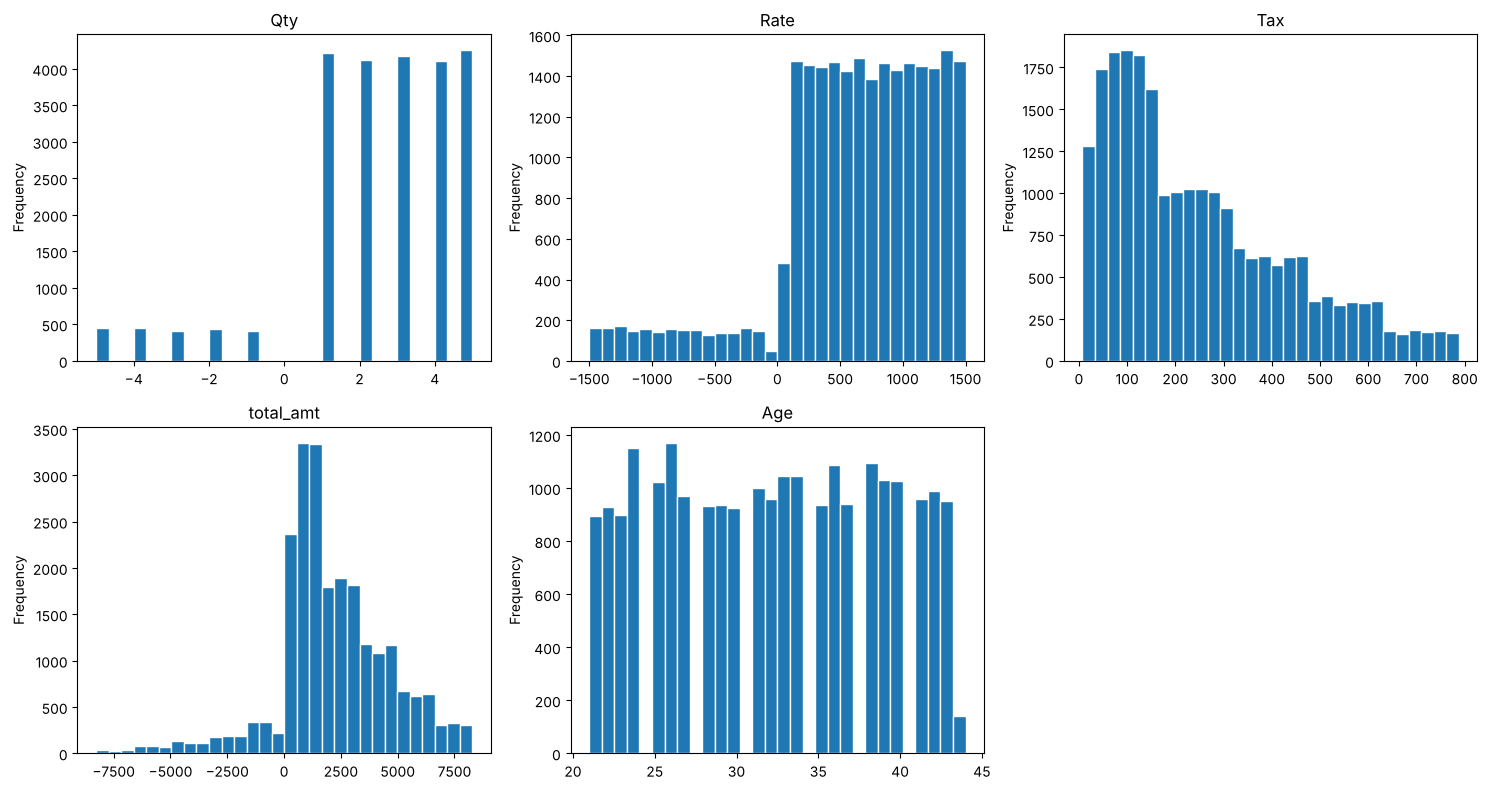

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, continuous):
    ax.hist(Customer_Final[col], bins=30, edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('Frequency')

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

### Frequency bars for categorical variables

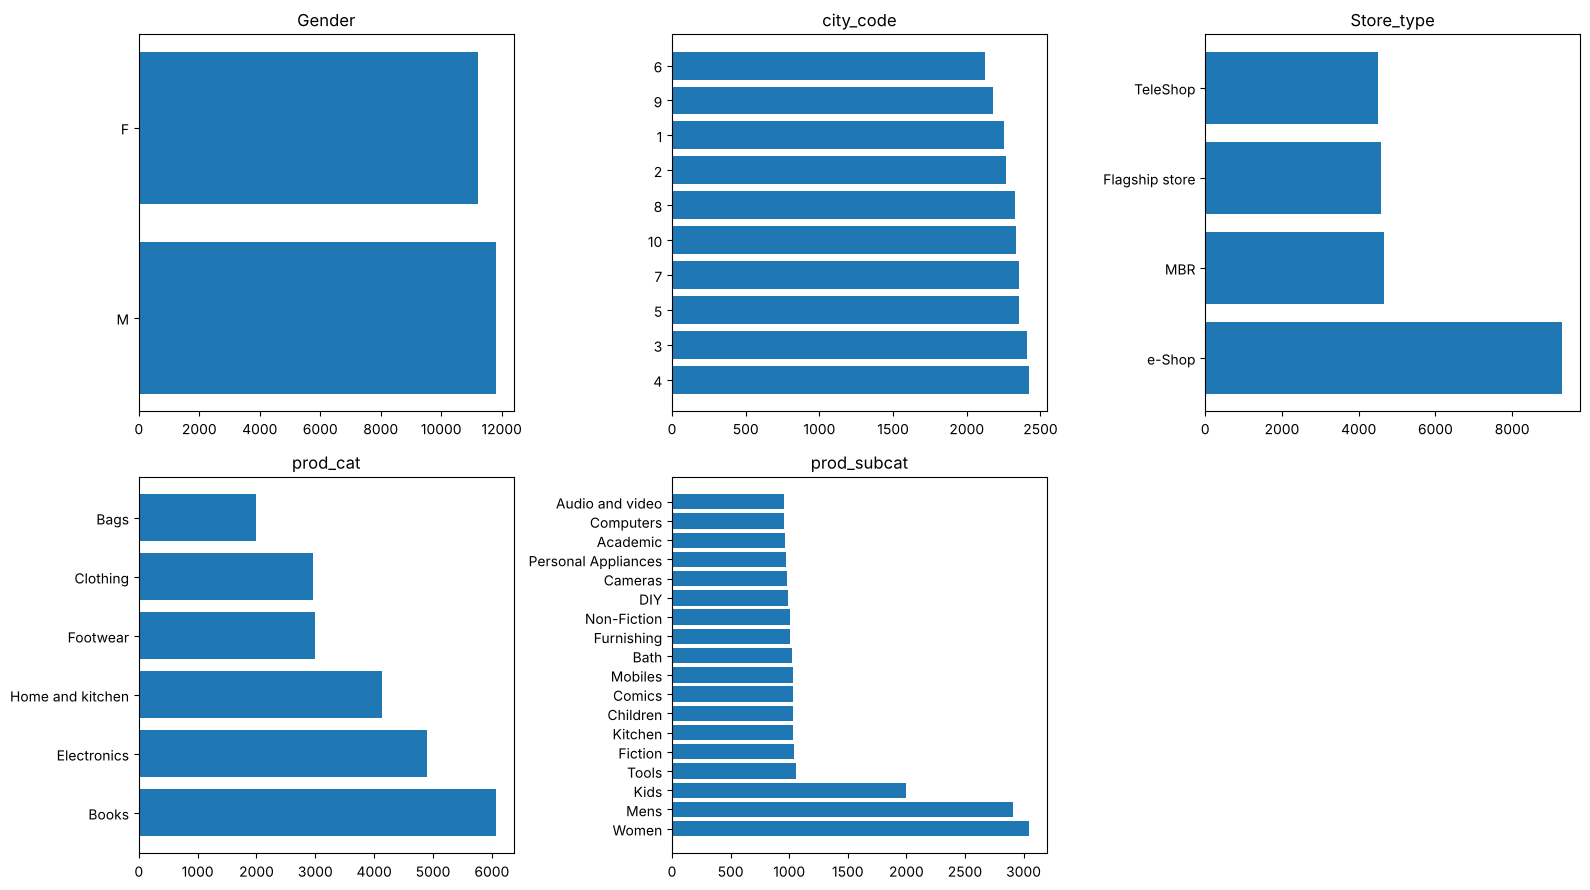

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, categorical):
    counts = Customer_Final[col].value_counts()
    ax.barh(counts.index.astype(str), counts.values)
    ax.set_title(col)

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## Q4. Time period and negative transactions
### 4a. Time period

In [21]:
start = Customer_Final['tran_date'].min()
end = Customer_Final['tran_date'].max()
days = (end - start).days

print('Start:', start.date())
print('End  :', end.date())
print('Days :', days)

Start: 2011-01-25
End  : 2014-02-28
Days : 1130


### 4b. Negative transactions (returns)

In [22]:
negative = (Customer_Final['total_amt'] < 0).sum()
print('Negative transactions:', negative)
print('Share of all transactions:', round(negative / len(Customer_Final) * 100, 2), '%')

Negative transactions: 2164
Share of all transactions: 9.39 %


## Q5. Category preference by gender
Purchases only (returns excluded), shown as each category's % share of that gender's units.

In [23]:
sales = Customer_Final[Customer_Final['Qty'] > 0]

gender_cat = pd.crosstab(sales['prod_cat'], sales['Gender'],
                         values=sales['Qty'], aggfunc='sum')

gender_share = (gender_cat / gender_cat.sum() * 100).round(2)
gender_share

Gender,F,M
prod_cat,,
Bags,8.81,8.28
Books,26.01,26.31
Clothing,12.72,13.01
Electronics,20.95,22.28
Footwear,13.60,12.36
Home and kitchen,17.93,17.76


## Q6. City with the most customers

In [24]:
city_customers = Customer_Final.groupby('city_code')['cust_id'].nunique()
city_customers = city_customers.sort_values(ascending=False)

total_customers = Customer_Final['cust_id'].nunique()

print('Top city:', city_customers.index[0])
print('Customers:', city_customers.iloc[0])
print('Percentage:', round(city_customers.iloc[0] / total_customers * 100, 2), '%')

Top city: 3
Customers: 576
Percentage: 10.46 %


## Q7. Store type sales (by value and quantity, net of returns)

In [25]:
store = Customer_Final.groupby('Store_type')[['total_amt', 'Qty']].sum()
store = store.sort_values('total_amt', ascending=False)

print('Top by value   :', store['total_amt'].idxmax())
print('Top by quantity:', store['Qty'].idxmax())
store

Top by value   : e-Shop
Top by quantity: e-Shop


,total_amt,Qty
Store_type,,
e-Shop,"19,842,623.12",22790
Flagship store,"9,721,596.62",11142
MBR,"9,674,941.31",11195
TeleShop,"9,372,133.74",10993


## Q8. Flagship stores: Electronics and Clothing

In [26]:
q8 = Customer_Final[(Customer_Final['Store_type'] == 'Flagship store') &
                    (Customer_Final['prod_cat'].isin(['Electronics', 'Clothing']))]

print(q8.groupby('prod_cat')['total_amt'].sum())
print('Total:', round(q8['total_amt'].sum(), 2))

prod_cat
Clothing      1,194,423.23
Electronics   2,215,136.04
Name: total_amt, dtype: float64
Total: 3409559.27


## Q9. Male customers, Electronics

In [27]:
q9 = Customer_Final.loc[(Customer_Final['Gender'] == 'M') &
                        (Customer_Final['prod_cat'] == 'Electronics'), 'total_amt'].sum()
print('Male, Electronics:', round(q9, 2))

Male, Electronics: 5711351.62


## Q10. Customers with more than 10 unique transactions (negatives removed)

In [28]:
positive = Customer_Final[Customer_Final['total_amt'] > 0]

txn_per_cust = positive.groupby('cust_id')['transaction_id'].nunique()

print('Customers with >10 transactions:', (txn_per_cust > 10).sum())

Customers with >10 transactions: 6


## Q11. Customers aged 25 to 35

In [29]:
age_group = Customer_Final[Customer_Final['Age'].between(25, 35)]

# Q11a: Electronics and Books
q11a = age_group[age_group['prod_cat'].isin(['Electronics', 'Books'])]
print(q11a.groupby('prod_cat')['total_amt'].sum())
print('Q11a Total:', round(q11a['total_amt'].sum(), 2))

# Q11b: 1 Jan 2014 to 1 Mar 2014
q11b = age_group[age_group['tran_date'].between('2014-01-01', '2014-03-01')]
print('Q11b Total:', round(q11b['total_amt'].sum(), 2))

prod_cat
Books         5,996,786.38
Electronics   5,151,000.59
Name: total_amt, dtype: float64
Q11a Total: 11147786.98
Q11b Total: 1080712.1


## Key Findings

1. **Data:** 23,040 transactions from 5,506 customers, Jan 2011 to Feb 2014 (after removing 13 duplicate rows).
2. **Returns:** 2,164 transactions (9.4%) are returns, so all revenue figures are net of returns.
3. **Channel:** e-Shop is the strongest store type, about 19.8M in net sales, roughly double each other channel.
4. **Customers by city:** City 3 has the most customers (576, 10.46%), but all 10 cities are nearly equal.
5. **Gender:** men and women buy almost the same category mix (largest gap 1.3 percentage points), so gender is a weak basis for product targeting.

## Assumptions
- Products were joined on category + sub-category code, because sub-category codes repeat across categories.
- Age was calculated as of the last transaction date (28 Feb 2014), not today.
- Two customers with missing gender or city were kept in totals.